# Spectral Clustering

A Gaussian affinity graph gives nearby points on each ring much larger edge weights. Spectral clustering uses the graph eigenvectors to separate the inner and outer circles.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Fit the grouping

The generator supplies reference labels for scoring. The estimator sees only the coordinates.

In [2]:
import matplotlib.pyplot as plt
from sklearn.cluster import SpectralClustering
from gallery.unsupervised import cluster_data, cluster_report

## Point cloud

In [3]:
X, reference = cluster_data("rings")
model = SpectralClustering(
    n_clusters=2, affinity="rbf", gamma=32, assign_labels="cluster_qr", random_state=17
)
labels = model.fit_predict(X)

## Group quality

External scores include every observation. Internal scores are calculated on assigned points.

Clusters: 2 | Assigned: 100.0% | Noise points: 0
Adjusted Rand index (all): 1.000
Adjusted mutual information (all): 1.000
Silhouette (assigned): 0.160
Davies–Bouldin (assigned): 179.232
Calinski–Harabasz (assigned): 0.0


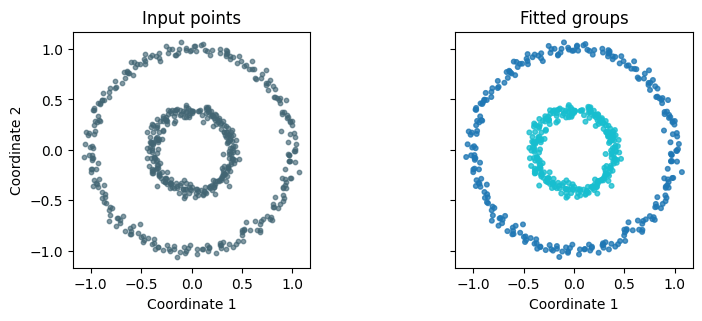

In [4]:
cluster_report(X, reference, labels)
plt.show()

## Reading the result

The adjusted Rand index compares fitted groups with the generating labels. The silhouette measures compactness, which can penalise a correctly recovered crescent or ring.

## References

[scikit-learn, SpectralClustering](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.SpectralClustering.html)

[scikit-learn, make_circles](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_circles.html)

[scikit-learn, clustering algorithms and evaluation](https://scikit-learn.org/stable/modules/clustering.html)

[Dataset generators and evaluation](../../../gallery/unsupervised.py)